    # Oficina de Machine Learning | Classificação: quais clientes vão cancelar?

**Prof. Mateus Henrique Zeiser**
ABEX VI: Projeto Integrado III | Aula 12 (29/10/2026) | Sistemas de Informação

    ## Objetivo
    Na aula 11, a árvore de decisão foi treinada à mão com 12 clientes da FluxoPlay. Aqui o mesmo fluxo é feito em código, com uma base **real** de uma empresa de assinaturas: prever quais clientes vão cancelar e decidir quem recebe uma ação de retenção. Depois, o grupo adapta este notebook à base do próprio projeto (seção 11).

    ## Base de dados
    IBM Telco Customer Churn, base pública da IBM (também no Kaggle). 7.043 clientes de uma operadora de telefonia e internet; cada linha é um cliente, com o que se sabia dele no fim do mês e se ele cancelou no mês seguinte.

    | Variável | Descrição |
    |---|---|
    | `customerID` | Identificador do cliente |
    | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Perfil: sexo, idoso (0/1), tem cônjuge, tem dependentes |
    | `tenure` | Meses como cliente |
    | `PhoneService`, `MultipleLines` | Telefone e múltiplas linhas |
    | `InternetService` | Tipo de internet (DSL, fibra ou nenhuma) |
    | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Serviços adicionais |
    | `Contract` | Tipo de contrato (mensal, 1 ano, 2 anos) |
    | `PaperlessBilling`, `PaymentMethod` | Fatura digital e forma de pagamento |
    | `MonthlyCharges`, `TotalCharges` | Valor mensal e valor total pago (USD) |
    | `Churn` | Cancelou (Yes/No): o **alvo** |

## Roteiro
| Seção | Etapa | Pergunta | Etapa da aula 11 |
|---|---|---|---|
| 0 | Configuração e carregamento | De onde vêm os dados e o que se quer prever? | 1. Problema |
| 1 | Auditoria inicial da base | Há problemas de tipo, ausência, duplicata ou consistência? | 2. Dados |
| 2 | Divisão treino e teste | Como separar os dados antes de tomar decisões? | 5. Treino e teste |
| 3 | EDA inicial (no treino) | O que os dados mostram sobre o alvo? | 3. Variáveis |
| 4 | Pré-processamento | O que precisa ser transformado, e por quê? | 4. Preparação |
| 5 | EDA de validação | O pré-processamento fez o que deveria? Há vazamento? | 4. Preparação |
| 6 | Modelagem | Qual modelo e qual complexidade generalizam melhor? | 6. Treinamento |
| 7 | Avaliação final no teste | Qual o desempenho em dados nunca vistos? | 7. Previsões e 8. Avaliação |
| 8 | Análise de erros e interpretação | Onde o modelo erra e o que ele aprendeu? | 9. Interpretação |
| 9 | Conclusões | | |
| 10 | Desafios | | |
| 11 | Entrega: adaptação ao projeto do grupo | | |

Sequência correta vista em aula: (1) limpar o que é regra fixa, (2) separar treino e teste, (3) ajustar as transformações só no treino, (4) escolher o modelo sem olhar o teste, (5) usar o teste uma única vez.

## Como este notebook será usado no projeto

O notebook está pronto e roda do início ao fim com a base de exemplo. Na seção 11, o grupo faz uma cópia e o adapta à base do projeto. O código das seções 2 a 8 não precisa ser reescrito: ele funciona com qualquer base em que uma linha é uma observação e uma coluna é o alvo.

| Onde | O que o grupo modifica |
|---|---|
| 0. Parâmetros | arquivo, alvo, classe positiva, colunas que ficam fora do modelo, custos |
| 1.3 Função `limpar` | as regras fixas de limpeza da base do projeto |
| 4.1 Função `criar_atributos` | as novas variáveis que fazem sentido no projeto (ou nenhuma) |
| Células de texto marcadas com **Leitura** | reescritas com o que os dados do projeto mostram |
| 3.8 e 9 | tabela de achados e decisões e conclusões do projeto |

# 0. Configuração e carregamento

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

## Parâmetros do problema

Esta é a célula que muda quando o notebook é usado em outra base. O **alvo** é o que se quer prever; a **classe positiva** é o evento que se quer detectar (aula 11: positivo não quer dizer bom). Os custos vêm do negócio: quanto custa agir sobre um alerta e quanto custa deixar passar um caso positivo.

In [2]:
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
ALVO = 'Churn'                  # coluna que se quer prever
CLASSE_POSITIVA = 'Yes'         # valor do alvo que representa o evento a detectar
COLUNAS_FORA = ['customerID']   # identificadores e colunas que só existem depois do evento
PROPORCAO_TESTE = 0.25          # parte da base guardada para a avaliação final
CUSTO_ACAO = 50                 # custo de cada alerta: desconto oferecido para reter o cliente (USD)
CUSTO_PERDA = 200               # custo de cada cancelamento não detectado: receita perdida (USD)
SEED = 42

In [3]:
# Upload de arquivo no Google Colab (opcional).
# Por padrão o notebook baixa a base pública pela internet.
# Para usar um arquivo seu, descomente as três linhas abaixo, rode a célula e escolha o arquivo.

# from google.colab import files
# enviados = files.upload()
# ARQUIVO_LOCAL = list(enviados.keys())[0]

ARQUIVO_LOCAL = globals().get('ARQUIVO_LOCAL', None)
print('Arquivo local:', ARQUIVO_LOCAL if ARQUIVO_LOCAL else 'nenhum, será usada a base pública')

Arquivo local: nenhum, será usada a base pública


In [4]:
df_bruto = pd.read_csv(ARQUIVO_LOCAL if ARQUIVO_LOCAL else URL, sep=None, engine='python')   # para .xlsx: pd.read_excel(ARQUIVO_LOCAL)
print('Shape:', df_bruto.shape)
df_bruto.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


# 1. Auditoria inicial da base

## 1.1 Estrutura e tipos de atributo

In [5]:
df_bruto.info()
pd.DataFrame({'dtype': df_bruto.dtypes.astype(str), 'distintos': df_bruto.nunique(),
              'exemplo': [df_bruto[c].dropna().iloc[0] for c in df_bruto.columns]})

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,dtype,distintos,exemplo
customerID,str,7043,7590-VHVEG
gender,str,2,Female
SeniorCitizen,int64,2,0
Partner,str,2,Yes
Dependents,str,2,No
tenure,int64,73,1
PhoneService,str,2,No
MultipleLines,str,3,No phone service
InternetService,str,3,DSL
OnlineSecurity,str,3,No


**Leitura.** Três problemas de tipo: `TotalCharges` é numérica, mas foi lida como texto (`str`), o que indica algum valor que não é número. `SeniorCitizen` é categórica (sim ou não) codificada como 0 e 1. `customerID` tem um valor diferente em cada linha: é um identificador e fica fora do modelo (`COLUNAS_FORA`).

## 1.2 Qualidade dos dados

| Dimensão | Verificação |
|---|---|
| Completude | NaN e ausentes disfarçados (texto vazio, `?`, `NA`) |
| Unicidade | Linhas repetidas e identificadores repetidos |
| Consistência | Categorias escritas de formas diferentes ou que dizem a mesma coisa |

In [6]:
# Completude: NaN e ausentes "disfarçados" (texto vazio, '?', 'NA'...), que o pandas não reconhece.
disfarcados = ['', ' ', '?', 'na', 'n/a', 'nan', 'none', 'null', '-']
tab_ausentes = pd.DataFrame({
    'NaN': df_bruto.isnull().sum(),
    '% NaN': (100 * df_bruto.isnull().mean()).round(2),
    'disfarçados': [df_bruto[c].astype(str).str.strip().str.lower().isin(disfarcados).sum()
                    if not pd.api.types.is_numeric_dtype(df_bruto[c]) else 0 for c in df_bruto.columns],
})
display(tab_ausentes)
print('Linhas duplicadas (iguais em todas as colunas):', df_bruto.duplicated().sum())

,NaN,% NaN,disfarçados
customerID,0,0.000,0
gender,0,0.000,0
SeniorCitizen,0,0.000,0
Partner,0,0.000,0
Dependents,0,0.000,0
tenure,0,0.000,0
PhoneService,0,0.000,0
MultipleLines,0,0.000,0
InternetService,0,0.000,0
OnlineSecurity,0,0.000,0


Linhas duplicadas (iguais em todas as colunas): 0


In [7]:
texto = df_bruto.select_dtypes(exclude='number').drop(columns=COLUNAS_FORA + [ALVO], errors='ignore')
for c in texto.columns:
    print(f'{c:<18}', sorted(texto[c].astype(str).unique())[:8])

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
TotalCharges       [' ', '100.2', '100.25', '100.35', '100.4', '100.8', '100.9', '1001.2']


In [8]:
# Específico da base de exemplo: no projeto, apague ou adapte esta célula.
branco = df_bruto['TotalCharges'].astype(str).str.strip() == ''
print('TotalCharges em branco:', branco.sum())
display(df_bruto.loc[branco, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])
print('Clientes com InternetService = No:', (df_bruto['InternetService'] == 'No').sum(),
      '| com OnlineSecurity = "No internet service":', (df_bruto['OnlineSecurity'] == 'No internet service').sum())

TotalCharges em branco: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.550,,No
753,3115-CZMZD,0,20.250,,No
936,5709-LVOEQ,0,80.850,,No
1082,4367-NUYAO,0,25.750,,No
1340,1371-DWPAZ,0,56.050,,No
3331,7644-OMVMY,0,19.850,,No
3826,3213-VVOLG,0,25.350,,No
4380,2520-SGTTA,0,20.000,,No
5218,2923-ARZLG,0,19.700,,No
6670,4075-WKNIU,0,73.350,,No


Clientes com InternetService = No: 1526 | com OnlineSecurity = "No internet service": 1526


**Leitura.** - Não há NaN, mas há 11 **ausentes disfarçados** em `TotalCharges`: textos em branco, todos de clientes com `tenure = 0`. Eles acabaram de entrar e ainda não pagaram nenhuma fatura: o valor correto é 0, e não a média ou a mediana. É uma regra de domínio, aplicada na limpeza.
- `No internet service` aparece exatamente nos 1.526 clientes com `InternetService = No` (o mesmo vale para `No phone service`). A informação já está em `InternetService` e `PhoneService`: nos serviços adicionais, ela equivale a `No`.
- Não há linhas repetidas.

## 1.3 Limpeza determinística

Só entram aqui **regras fixas**, que não dependem de estatísticas dos dados (média, mediana, frequência) e por isso podem ser aplicadas antes de separar treino e teste. Tudo o que depende de estatísticas fica para o pipeline (seção 4), ajustado só no treino.

In [9]:
def limpar(d):
    d = d.copy()
    # Regras gerais (servem para qualquer base): texto sem espaços nas pontas e vazio como ausente.
    for c in d.select_dtypes(exclude='number').columns:
        d[c] = d[c].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan, 'None': np.nan})
    d = d.drop_duplicates()
    # Regras desta base (no projeto, reescreva este bloco):
    d['TotalCharges'] = pd.to_numeric(d['TotalCharges'], errors='coerce')
    d.loc[d['tenure'] == 0, 'TotalCharges'] = 0                      # clientes novos ainda não pagaram
    d['SeniorCitizen'] = d['SeniorCitizen'].map({0: 'No', 1: 'Yes'})  # categoria codificada como número
    d = d.replace({'No internet service': 'No', 'No phone service': 'No'})
    return d

df = limpar(df_bruto)
y = (df[ALVO] == CLASSE_POSITIVA).astype(int)
X = df.drop(columns=[ALVO] + COLUNAS_FORA)
print(f'Linhas: {len(df_bruto)} -> {len(df)} | features: {X.shape[1]} | classe positiva: {ALVO} = {CLASSE_POSITIVA!r} (y = 1)')
print('Ausentes depois da limpeza:', int(X.isnull().sum().sum()))

Linhas: 7043 -> 7043 | features: 19 | classe positiva: Churn = 'Yes' (y = 1)
Ausentes depois da limpeza: 0


# 2. Divisão treino e teste

O teste fica "trancado na gaveta" (aula 11) até a seção 7. A divisão é **estratificada**: treino e teste com a mesma proporção da classe positiva.

In [10]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=PROPORCAO_TESTE, stratify=y, random_state=SEED)
print(f'Treino: {len(X_treino)} linhas | Teste: {len(X_teste)} linhas')
pd.DataFrame({'treino': y_treino.value_counts(normalize=True), 'teste': y_teste.value_counts(normalize=True)}).round(3)

Treino: 5282 linhas | Teste: 1761 linhas


,treino,teste
Churn,,
0,0.735,0.735
1,0.265,0.265


# 3. EDA inicial (no treino)

## 3.1 Variável alvo e modelo de referência

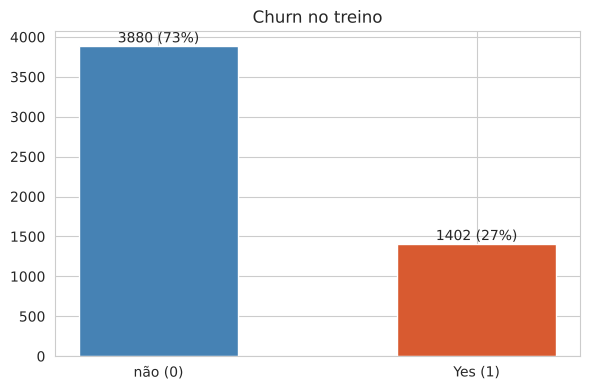

Referência: responder sempre a classe mais frequente acerta 73.5% e encontra 0% dos casos positivos.


In [11]:
eda = X_treino.assign(alvo=y_treino.values)
NUM = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
CAT = [c for c in X.columns if c not in NUM]
cont = y_treino.value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(['não (0)', f'{CLASSE_POSITIVA} (1)'], cont.values, color=['steelblue', '#D85A30'], width=0.5)
for j, v in enumerate(cont.values):
    plt.text(j, v + len(eda) * 0.01, f'{v} ({v / len(eda):.0%})', ha='center')
plt.title(f'{ALVO} no treino')
plt.tight_layout()
plt.show()
print(f'Referência: responder sempre a classe mais frequente acerta {max(y_treino.mean(), 1 - y_treino.mean()):.1%} e encontra 0% dos casos positivos.')

**Leitura.** A base é desbalanceada: cerca de 1 em cada 4 clientes cancela (26,5%). Um modelo que responde sempre "não cancela" acerta 73,5% e não encontra nenhum cancelamento. Esse é o piso de acurácia, e a acurácia sozinha não basta para avaliar o modelo (paradoxo da acurácia, aula 11).

## 3.2 Variáveis numéricas

,n,média,mediana,desvio padrão,mín,Q1,Q3,máx,IQR,assimetria,outliers (IQR),% outliers
tenure,"5,282.000",32.360,29.000,24.630,0.000,9.000,55.750,72.000,46.750,0.240,0.000,0.000
MonthlyCharges,"5,282.000",64.860,70.500,30.170,18.400,35.450,89.990,118.750,54.540,-0.220,0.000,0.000
TotalCharges,"5,282.000","2,292.080","1,385.300","2,285.170",0.000,391.060,"3,841.640","8,684.800","3,450.580",0.950,0.000,0.000


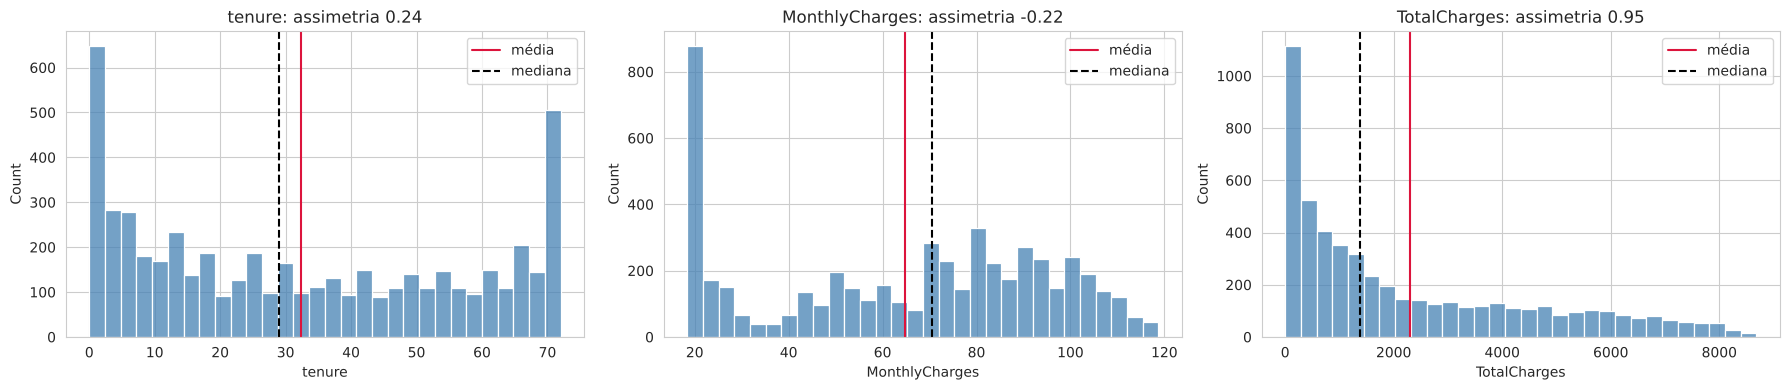

In [12]:
def resumo_numerico(dados):
    # Centro, dispersão, forma e extremos (medidas vistas na aula de EDA).
    linhas = {}
    for c in dados.columns:
        x = dados[c].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
        linhas[c] = {'n': len(x), 'média': x.mean(), 'mediana': x.median(), 'desvio padrão': x.std(),
                     'mín': x.min(), 'Q1': q1, 'Q3': q3, 'máx': x.max(), 'IQR': iqr,
                     'assimetria': x.skew(), 'outliers (IQR)': n_out, '% outliers': 100 * n_out / len(x)}
    return pd.DataFrame(linhas).T

def outliers_iqr(x):
    # Regra do boxplot: fora de [Q1 - 1,5*IQR ; Q3 + 1,5*IQR]
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

def outliers_desvio(x, k=3):
    # Regra do desvio padrão: mais de k desvios da média (z-score)
    return ((x - x.mean()) / x.std()).abs() > k


display(resumo_numerico(eda[NUM]).round(2))
fig, axes = plt.subplots(1, len(NUM), figsize=(6 * len(NUM), 4), squeeze=False)
for ax, c in zip(axes[0], NUM):
    sns.histplot(eda[c].dropna(), bins=30, ax=ax, color='steelblue')
    ax.axvline(eda[c].mean(), color='crimson', lw=1.5, label='média')
    ax.axvline(eda[c].median(), color='black', ls='--', lw=1.5, label='mediana')
    ax.set_title(f'{c}: assimetria {eda[c].skew():.2f}')
    ax.legend()
plt.tight_layout()
plt.show()

**Leitura.** - `tenure` tem dois grupos: muitos clientes novos e muitos com perto de 72 meses, o máximo da base.
- `MonthlyCharges` tem um pico perto de 20 USD (só telefone) e uma massa entre 70 e 100 USD (com internet).
- `TotalCharges` é assimétrica à direita: muitos clientes recentes, que pagaram pouco até agora.

## 3.3 Variáveis categóricas

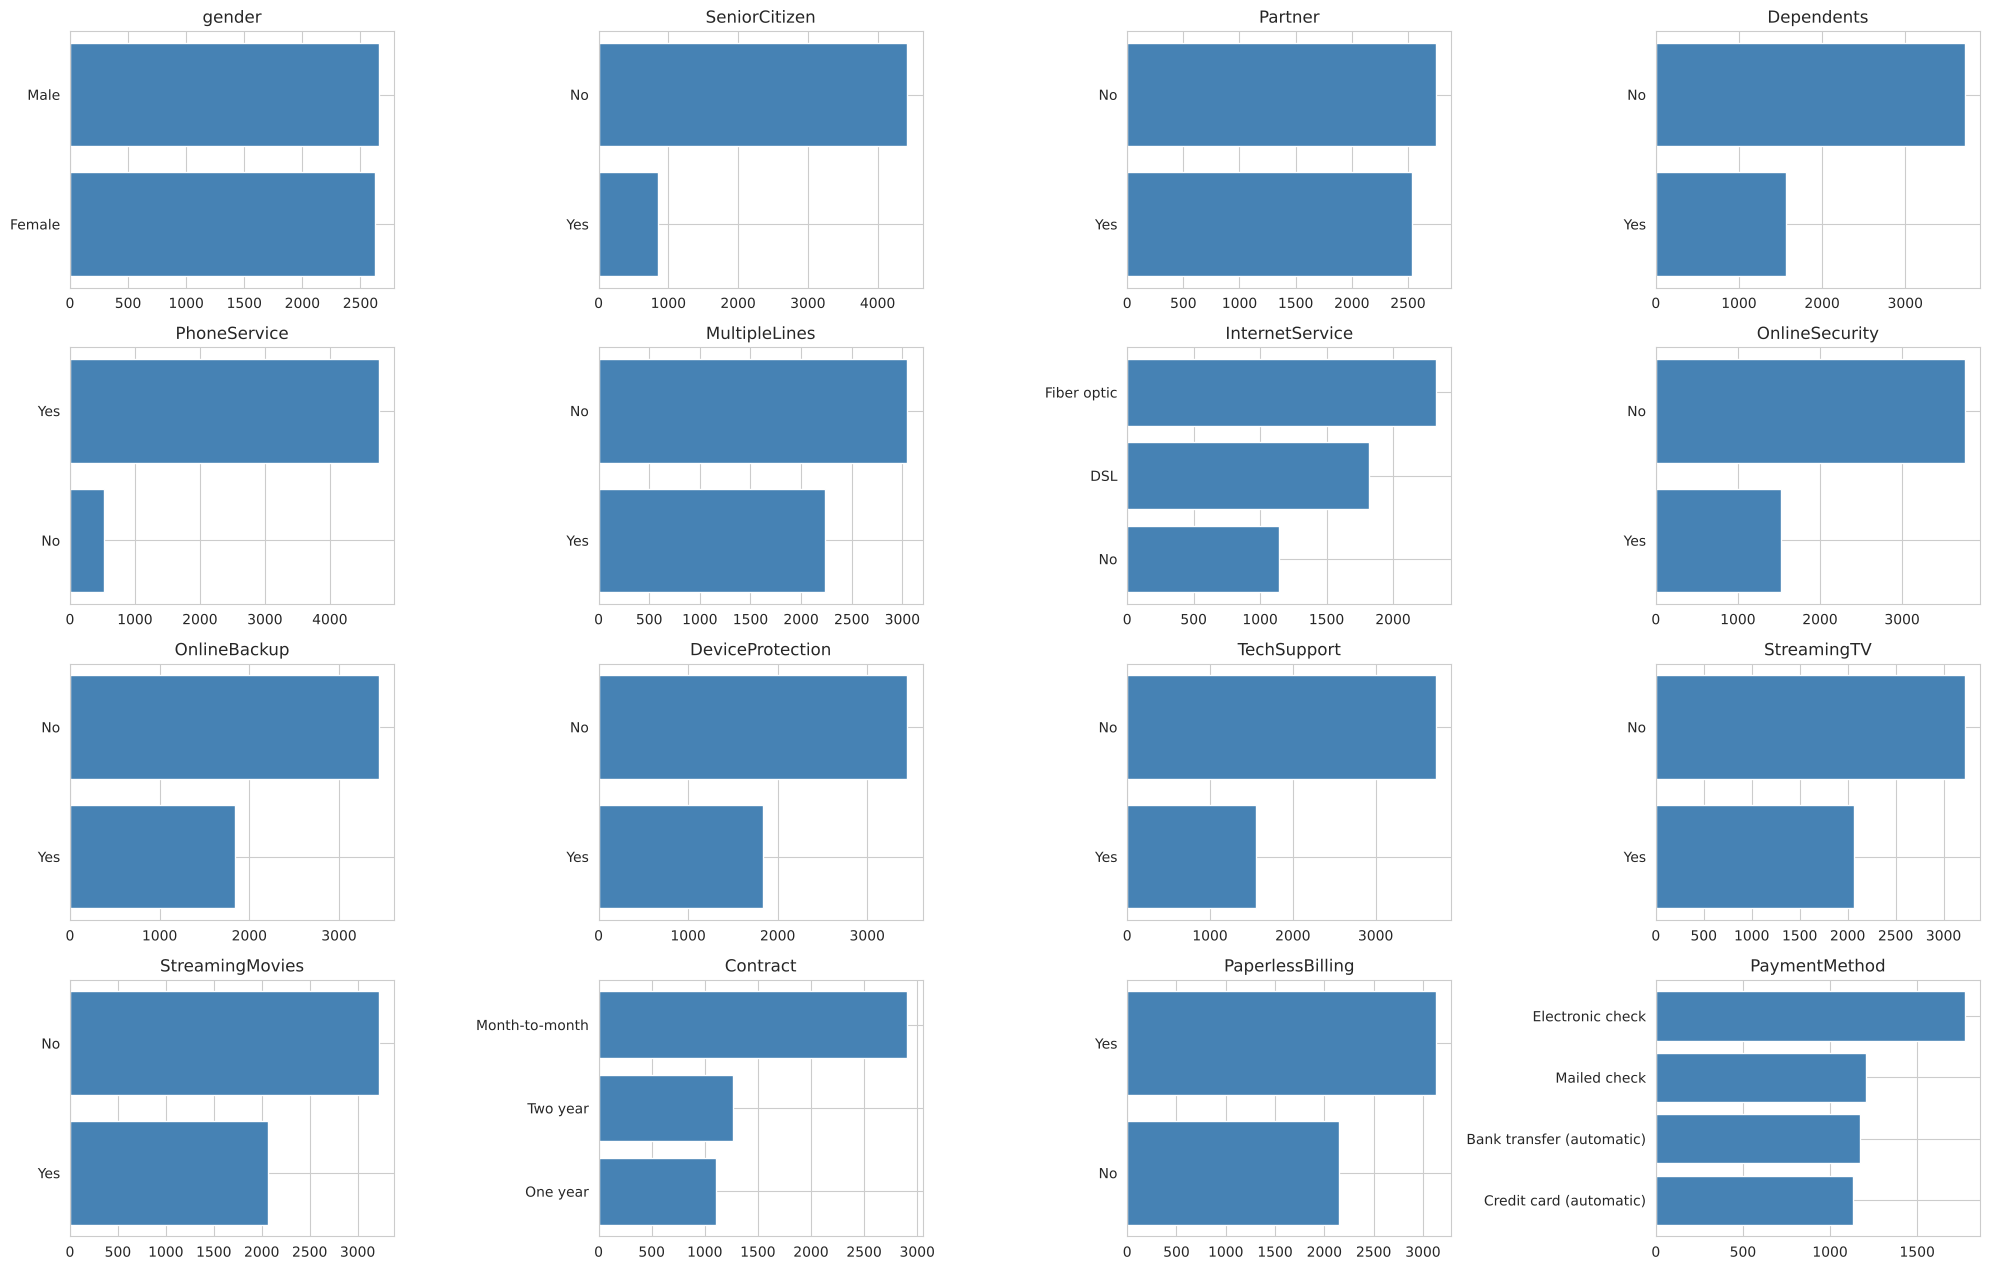

In [13]:
colunas = 4
linhas = int(np.ceil(len(CAT) / colunas))
fig, axes = plt.subplots(linhas, colunas, figsize=(5 * colunas, 3.2 * linhas), squeeze=False)
for ax, c in zip(axes.flat, CAT):
    freq = eda[c].value_counts().head(10)
    ax.barh(freq.index.astype(str)[::-1], freq.values[::-1], color='steelblue')
    ax.set_title(c)
for ax in axes.flat[len(CAT):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Leitura.** Depois da limpeza, quase todas as categóricas têm duas categorias. Não há categorias raras: as menores (`PhoneService = No`, `SeniorCitizen = Yes`) têm centenas de clientes.

## 3.4 Outliers: erro ou caso real?

In [14]:
pd.DataFrame({'outliers (IQR)': {c: int(outliers_iqr(eda[c].dropna()).sum()) for c in NUM},
              'outliers (|z| > 3)': {c: int(outliers_desvio(eda[c].dropna()).sum()) for c in NUM}})

,outliers (IQR),outliers (|z| > 3)
tenure,0,0
MonthlyCharges,0,0
TotalCharges,0,0


**Leitura.** Nenhuma das duas regras encontra outliers. A cauda de `TotalCharges` é longa, mas contínua, sem valores isolados: assimetria não é o mesmo que outlier.

## 3.5 Numéricas e o alvo

Com o alvo codificado como 0 e 1, a correlação de Pearson é positiva quando a variável tende a ser **maior** entre os casos positivos.

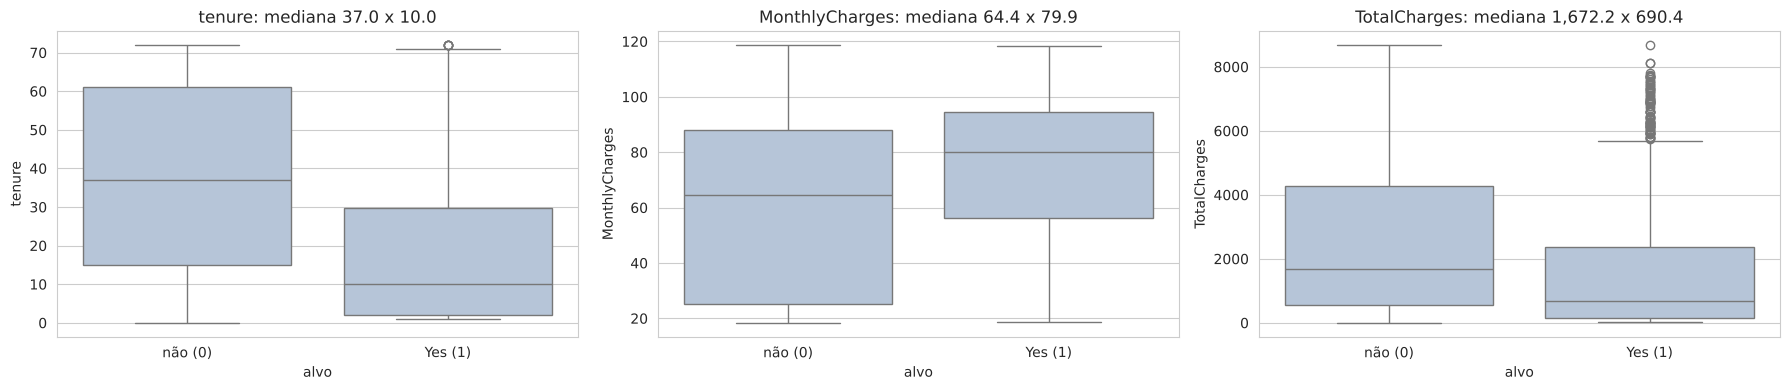

,Pearson com o alvo
tenure,-0.343
MonthlyCharges,0.197
TotalCharges,-0.192


In [15]:
fig, axes = plt.subplots(1, len(NUM), figsize=(6 * len(NUM), 4), squeeze=False)
for ax, c in zip(axes[0], NUM):
    sns.boxplot(data=eda, x='alvo', y=c, ax=ax, color='lightsteelblue')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['não (0)', f'{CLASSE_POSITIVA} (1)'])
    ax.set_title(f'{c}: mediana {eda.loc[eda.alvo == 0, c].median():,.1f} x {eda.loc[eda.alvo == 1, c].median():,.1f}')
plt.tight_layout()
plt.show()
eda[NUM].corrwith(eda['alvo']).sort_values(key=abs, ascending=False).round(3).to_frame('Pearson com o alvo')

**Leitura.** Quem cancela tem **menos tempo de casa** (mediana bem menor) e paga **mais por mês**. `tenure` tem a correlação mais forte com o alvo, e negativa. `TotalCharges` também é negativa porque acompanha o tempo de casa (3.7). As correlações são moderadas: nenhuma numérica separa as classes sozinha.

## 3.6 Categóricas e o alvo: taxa por categoria

Para cada categoria, a proporção de casos positivos. A **amplitude** (maior taxa menos menor taxa, entre categorias com pelo menos 30 linhas) ordena as variáveis pelo quanto separam as classes.

,amplitude da taxa
Contract,0.397
InternetService,0.348
PaymentMethod,0.304
PaperlessBilling,0.182
SeniorCitizen,0.177
OnlineSecurity,0.170
TechSupport,0.162
Dependents,0.161
Partner,0.129
OnlineBackup,0.077


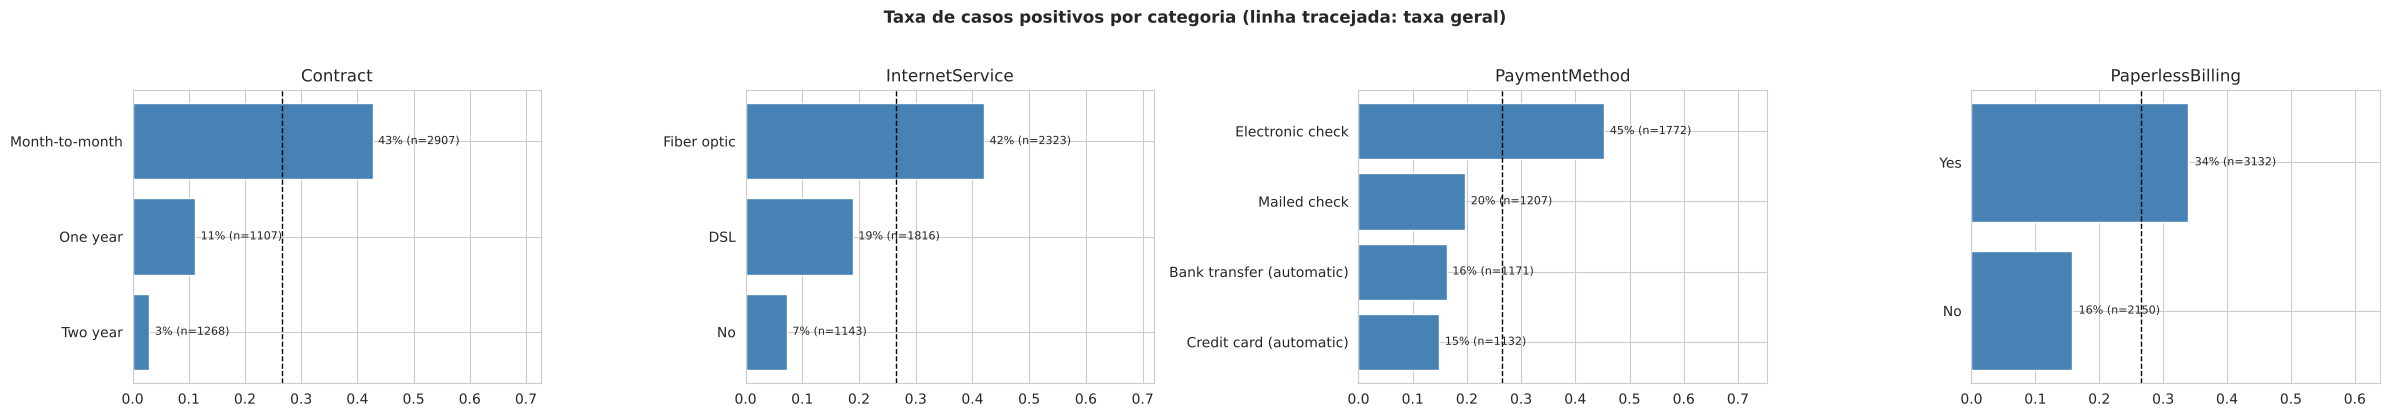

In [16]:
def taxa_por(col):
    return eda.groupby(col, observed=True)['alvo'].agg(n='count', taxa='mean').sort_values('taxa')

amplitude = pd.Series({c: taxa_por(c).query('n >= 30')['taxa'].agg(lambda s: s.max() - s.min()) for c in CAT}).sort_values(ascending=False)
display(amplitude.round(3).to_frame('amplitude da taxa'))

top = amplitude.index[:4]
fig, axes = plt.subplots(1, len(top), figsize=(6 * len(top), 4), squeeze=False)
for ax, c in zip(axes[0], top):
    t = taxa_por(c)
    ax.barh(t.index.astype(str), t['taxa'], color='steelblue')
    ax.axvline(eda['alvo'].mean(), color='black', ls='--', lw=1)
    for j, (tx, n) in enumerate(zip(t['taxa'], t['n'])):
        ax.text(tx + 0.01, j, f'{tx:.0%} (n={n})', va='center', fontsize=8)
    ax.set(xlim=(0, min(1, t['taxa'].max() + 0.3)), title=c)
plt.suptitle('Taxa de casos positivos por categoria (linha tracejada: taxa geral)', y=1.03, fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura.** - `Contract` é a variável que mais separa: 43% de cancelamento no contrato mensal, 11% no de um ano e 3% no de dois anos.
- Clientes com fibra ótica cancelam bem mais (42%) que os de DSL (19%), e quem paga por `Electronic check` cancela mais (45%) que nas outras formas de pagamento (15% a 20%).
- `gender` praticamente não separa (amplitude perto de zero).

## 3.7 Relações entre numéricas e discretização

A numérica mais correlacionada com o alvo é dividida em quatro faixas de mesmo tamanho (`pd.qcut`): a taxa por faixa mostra se o risco sobe ou desce de forma regular.

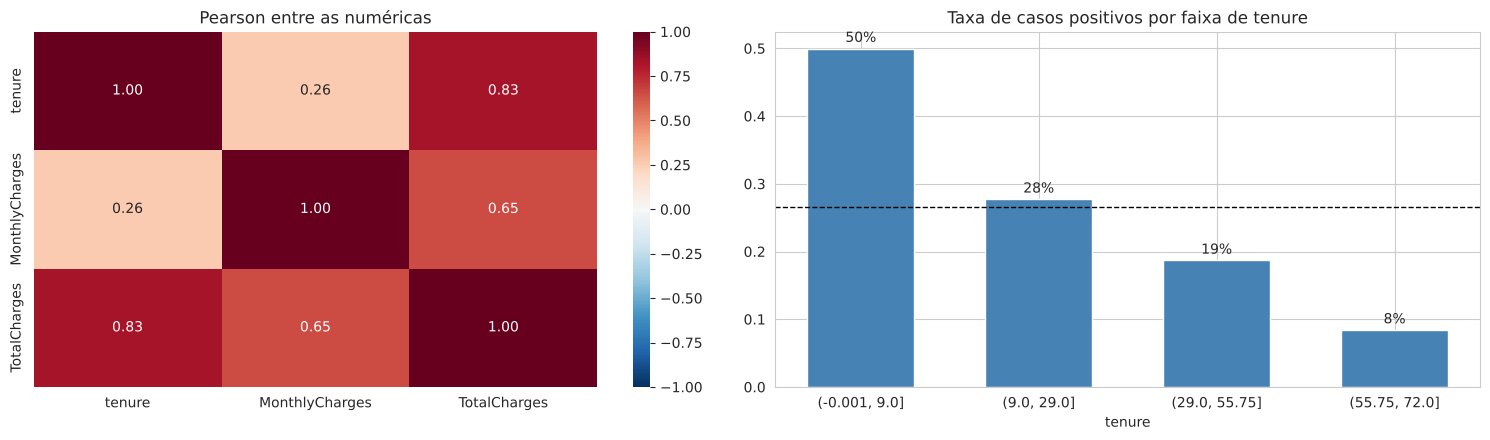

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(eda[NUM].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson entre as numéricas')
principal = eda[NUM].corrwith(eda['alvo']).abs().idxmax()
faixas = pd.qcut(eda[principal], 4, duplicates='drop')
t = eda.groupby(faixas, observed=True)['alvo'].agg(n='count', taxa='mean')
axes[1].bar(t.index.astype(str), t['taxa'], color='steelblue', width=0.6)
for j, (tx, n) in enumerate(zip(t['taxa'], t['n'])):
    axes[1].text(j, tx + 0.01, f'{tx:.0%}', ha='center')
axes[1].axhline(eda['alvo'].mean(), color='black', ls='--', lw=1)
axes[1].set(title=f'Taxa de casos positivos por faixa de {principal}', xlabel=principal)
plt.tight_layout()
plt.show()

**Leitura.** - `TotalCharges` tem Pearson de 0,83 com `tenure`: é quase tempo de casa vezes valor mensal. As duas carregam praticamente a mesma informação.
- A taxa de cancelamento cai de forma regular com o tempo de casa: 50% no primeiro quarto dos clientes (até 9 meses) e 8% no último. O risco se concentra no início do contrato.

    ## 3.8 Síntese: achados e decisões

| Achado | Evidência | Decisão |
|---|---|---|
| `TotalCharges` lida como texto; brancos de clientes novos | 1.1, 1.2 | `limpar`: converter para número e preencher com 0 |
| `SeniorCitizen` codificada como 0 e 1 | 1.1 | `limpar`: converter para Yes e No |
| `No internet service` repete `InternetService` | 1.2 | `limpar`: trocar por `No` |
| `customerID` é identificador | 1.1 | `COLUNAS_FORA` |
| Classes desbalanceadas (26,5% de cancelamentos) | 3.1 | divisão estratificada; avaliar recall, precisão e custo, além da acurácia |
| Contrato, internet e pagamento separam bem as classes | 3.6 | manter, com one-hot |
| Risco cai com o tempo de casa | 3.7 | criar faixas de tempo de casa (4.1) |
| Serviços de proteção e suporte reduzem o risco | 3.6 | criar `n_servicos` (4.1) |

# 4. Pré-processamento

## 4.1 Engenharia de atributos

Novas variáveis criadas com **regras fixas** (sem estatísticas dos dados), aplicadas igualmente a treino e teste. No projeto, troque por regras que façam sentido ou deixe a função só com `return X.copy()`.

In [18]:
SERVICOS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def criar_atributos(X):
    X = X.copy()
    X['n_servicos'] = (X[SERVICOS] == 'Yes').sum(axis=1)                               # serviços adicionais contratados
    X['faixa_tenure'] = pd.cut(X['tenure'], bins=[-1, 12, 24, 48, 72],
                               labels=['até 1 ano', '1 a 2 anos', '2 a 4 anos', '4 a 6 anos']).astype(str)
    return X

X_treino = criar_atributos(X_treino)
X_teste = criar_atributos(X_teste)
NUM = [c for c in X_treino.columns if pd.api.types.is_numeric_dtype(X_treino[c])]
CAT = [c for c in X_treino.columns if c not in NUM]
print('Numéricas:', NUM)
print('Categóricas:', CAT)

Numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_servicos']
Categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'faixa_tenure']


## 4.2 Pipeline de preparação

| Grupo | Passos | Por quê (aula 11) |
|---|---|---|
| Numéricas | faltantes preenchidos pela **mediana do treino** | a mediana é calculada só com o treino e aplicada ao teste |
| Categóricas | faltante vira a categoria `ausente`; cada categoria vira uma coluna 0/1 (one-hot) | a árvore só trabalha com números; a ausência pode ter significado |

A árvore de decisão não precisa de padronização (z-score): cada pergunta compara uma variável com um valor de corte, e a escala não muda a ordem dos valores.

In [19]:
def criar_preparo():
    return ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), NUM),
        ('categoricas', Pipeline([('ausente', SimpleImputer(strategy='constant', fill_value='ausente')),
                                  ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT)],
        verbose_feature_names_out=False)

def transformar(prep, dados):
    return pd.DataFrame(prep.transform(dados), columns=prep.get_feature_names_out(), index=dados.index)

preparo = criar_preparo().fit(X_treino)
Xtr_p, Xte_p = transformar(preparo, X_treino), transformar(preparo, X_teste)
print(f'{X_treino.shape[1]} colunas originais -> {Xtr_p.shape[1]} colunas depois do one-hot')
Xtr_p.head()

21 colunas originais -> 44 colunas depois do one-hot


,tenure,MonthlyCharges,TotalCharges,n_servicos,gender_Female,gender_Male,SeniorCitizen_No,SeniorCitizen_Yes,Partner_No,Partner_Yes,...,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,faixa_tenure_1 a 2 anos,faixa_tenure_2 a 4 anos,faixa_tenure_4 a 6 anos,faixa_tenure_até 1 ano
6661,72.000,53.650,"3,784.000",4.000,1.000,0.000,1.000,0.000,0.000,1.000,...,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000
4811,4.000,46.000,193.600,0.000,1.000,0.000,1.000,0.000,1.000,0.000,...,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000
2193,56.000,21.200,"1,238.650",0.000,0.000,1.000,1.000,0.000,1.000,0.000,...,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000
1904,56.000,94.450,"5,124.600",3.000,0.000,1.000,1.000,0.000,1.000,0.000,...,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000
6667,9.000,79.550,723.400,1.000,1.000,0.000,1.000,0.000,1.000,0.000,...,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000


# 5. EDA de validação

## 5.1 Integridade

In [20]:
checks = {
    'sem ausentes depois da preparação': int(Xtr_p.isnull().sum().sum() + Xte_p.isnull().sum().sum()) == 0,
    'treino e teste com as mesmas colunas': list(Xtr_p.columns) == list(Xte_p.columns),
    'treino e teste sem linhas em comum': len(set(X_treino.index) & set(X_teste.index)) == 0,
    'mesma proporção da classe positiva (diferença < 1 ponto)': abs(y_treino.mean() - y_teste.mean()) < 0.01,
    'alvo e colunas excluídas fora das features': not any(c in X_treino.columns for c in [ALVO] + COLUNAS_FORA),
}
pd.DataFrame({'resultado': {k: 'OK' if v else 'FALHOU' for k, v in checks.items()}})

,resultado
sem ausentes depois da preparação,OK
treino e teste com as mesmas colunas,OK
treino e teste sem linhas em comum,OK
mesma proporção da classe positiva (diferença < 1 ponto),OK
alvo e colunas excluídas fora das features,OK


## 5.2 Treino e teste continuam comparáveis?

In [21]:
display(pd.DataFrame({'média treino': X_treino[NUM].mean(), 'média teste': X_teste[NUM].mean(),
                      'mediana treino': X_treino[NUM].median(), 'mediana teste': X_teste[NUM].median()}).round(2))
c = amplitude.index[0]
pd.DataFrame({'treino': X_treino[c].value_counts(normalize=True), 'teste': X_teste[c].value_counts(normalize=True)}).round(3)

,média treino,média teste,mediana treino,mediana teste
tenure,32.360,32.400,29.000,29.000
MonthlyCharges,64.860,64.480,70.500,69.950
TotalCharges,"2,292.080","2,242.690","1,385.300","1,422.650"
n_servicos,2.060,1.980,2.000,2.000


,treino,teste
Contract,,
Month-to-month,0.550,0.550
Two year,0.240,0.242
One year,0.210,0.208


## 5.3 Verificação de vazamento

Pergunta da aula 11 para cada feature: *eu saberia este valor no momento da previsão?* Uma verificação prática: treinar uma árvore com **uma feature de cada vez**. Se uma única coluna prevê o alvo quase perfeitamente, ela provavelmente carrega informação do próprio alvo.

Para mostrar como o vazamento aparece, a célula acrescenta, numa cópia dos dados, uma coluna fictícia `motivo_saida`, que só seria preenchida para quem já cancelou.

In [22]:
def acuracia_uma_feature(Xa, ya, Xb, yb, coluna):
    cols_num = [coluna] if pd.api.types.is_numeric_dtype(Xa[coluna]) else []
    prep = ColumnTransformer([('n', SimpleImputer(strategy='median'), cols_num),
                              ('c', Pipeline([('a', SimpleImputer(strategy='constant', fill_value='ausente')),
                                              ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), [coluna] if not cols_num else [])])
    m = Pipeline([('p', prep), ('m', DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEED))]).fit(Xa[[coluna]], ya)
    return accuracy_score(yb, m.predict(Xb[[coluna]]))

# treino dividido em duas partes para não usar o teste
Xa, Xb, ya, yb = train_test_split(X_treino, y_treino, test_size=0.3, stratify=y_treino, random_state=SEED)
rng = np.random.default_rng(SEED)
Xa_demo = Xa.assign(motivo_saida=np.where(ya == 1, rng.choice(['preço', 'concorrente', 'atendimento'], len(ya)), None))
Xb_demo = Xb.assign(motivo_saida=np.where(yb == 1, rng.choice(['preço', 'concorrente', 'atendimento'], len(yb)), None))

referencia = max(yb.mean(), 1 - yb.mean())
vaz = pd.Series({c: acuracia_uma_feature(Xa_demo, ya, Xb_demo, yb, c) for c in list(X_treino.columns) + ['motivo_saida']})
vaz = vaz.sort_values(ascending=False).to_frame('acurácia só com esta feature')
vaz['acima da referência'] = vaz.iloc[:, 0] - referencia
vaz['alerta'] = np.where(vaz.iloc[:, 0] >= 0.97, 'POSSÍVEL VAZAMENTO', '')
print(f'Referência (classe mais frequente): {referencia:.3f}')
display(vaz.head(8))

Referência (classe mais frequente): 0.734


,acurácia só com esta feature,acima da referência,alerta
motivo_saida,1.000,0.266,POSSÍVEL VAZAMENTO
tenure,0.754,0.020,
TotalCharges,0.750,0.015,
Partner,0.734,0.000,
SeniorCitizen,0.734,0.000,
gender,0.734,0.000,
PhoneService,0.734,0.000,
Dependents,0.734,0.000,


**Leitura.** Nenhuma feature real prevê o cancelamento sozinha: a melhor, `tenure`, fica só 2 pontos acima da referência. Já a coluna fictícia `motivo_saida` acerta 100%: ela só existe para quem já cancelou, então "ter um motivo" é o próprio alvo. No dia da previsão, essa coluna estaria vazia para todos os clientes ativos e o modelo não funcionaria. No projeto, qualquer feature com alerta precisa ser investigada antes de entrar no modelo.

## 5.4 Categoria nova e valor ausente: o pipeline está preparado?

In [23]:
novo = X_teste.head(2).copy()
num0, cat0 = NUM[0], amplitude.index[0]
novo.loc[novo.index[0], num0] = np.nan
novo.loc[novo.index[1], cat0] = 'categoria que não existe no treino'
t = transformar(preparo, novo)
print(f'{num0} ausente -> preenchido com a mediana do treino: {t.iloc[0][num0]}')
print(f'Colunas de {cat0} para a categoria nova:', t.iloc[1][[k for k in t.columns if k.startswith(cat0 + "_")]].to_dict())

tenure ausente -> preenchido com a mediana do treino: 29.0
Colunas de Contract para a categoria nova: {'Contract_Month-to-month': 0.0, 'Contract_One year': 0.0, 'Contract_Two year': 0.0}


**Leitura.** O valor ausente recebe a mediana do treino (29 meses). A categoria desconhecida vira zeros em todas as colunas de `Contract`: o modelo não quebra, mas trata o cliente como se não tivesse nenhum dos contratos conhecidos. Em uso real, categorias novas precisam ser acompanhadas.

# 6. Modelagem

## 6.1 Protocolo e métricas

O teste continua guardado. Para escolher a complexidade da árvore e o limiar **sem olhar o teste**, o treino é dividido mais uma vez:

| Parte | Uso |
|---|---|
| **ajuste** (75% do treino) | treinar as árvores candidatas |
| **validação** (25% do treino) | comparar as candidatas e escolher profundidade e limiar |
| **teste** | usado uma única vez, na seção 7 |

| | previsto negativo (0) | previsto positivo (1) |
|---|---|---|
| **real negativo (0)** | VN | FP: alerta desnecessário |
| **real positivo (1)** | FN: caso perdido | VP: alerta certo |

| Métrica | Fórmula | Pergunta |
|---|---|---|
| Acurácia | (VP + VN) / total | Quantas previsões estão certas? (engana com classes desbalanceadas) |
| Precisão | VP / (VP + FP) | Dos alertas, quantos estavam certos? |
| Recall | VP / (VP + FN) | Dos casos positivos, quantos foram encontrados? |
| Custo | (VP + FP) x CUSTO_ACAO + FN x CUSTO_PERDA | Quanto a decisão custa? |

In [24]:
X_aj, X_val, y_aj, y_val = train_test_split(X_treino, y_treino, test_size=0.25, stratify=y_treino, random_state=SEED)
print(f'Ajuste: {len(X_aj)} | Validação: {len(X_val)} | Teste (guardado): {len(X_teste)}')

MIN_FOLHA = 20   # mínimo de clientes em cada folha (a regra de parada da aula 11)

def arvore(profundidade, min_folha=None):
    return Pipeline([('preparo', criar_preparo()),
                     ('modelo', DecisionTreeClassifier(max_depth=profundidade, min_samples_leaf=min_folha or MIN_FOLHA, random_state=SEED))])

def metricas(y_real, prev):
    vp = int(((prev == 1) & (y_real == 1)).sum())
    fp = int(((prev == 1) & (y_real == 0)).sum())
    fn = int(((prev == 0) & (y_real == 1)).sum())
    return {'acurácia': accuracy_score(y_real, prev), 'precisão': precision_score(y_real, prev, zero_division=0),
            'recall': recall_score(y_real, prev), 'alertas': vp + fp, 'VP': vp, 'FN': fn,
            'custo': (vp + fp) * CUSTO_ACAO + fn * CUSTO_PERDA}

def tabela(resultados):
    return pd.DataFrame(resultados).T.astype({'alertas': int, 'VP': int, 'FN': int, 'custo': int})

Ajuste: 3961 | Validação: 1321 | Teste (guardado): 1761


## 6.2 Referência e regra simples

Dois pontos de comparação: a **referência** (sempre a classe mais frequente) e a **melhor regra de uma pergunta**, que é uma árvore com profundidade 1. Na aula 11, a primeira pergunta escolhida foi "atrasos >= 2?".

In [25]:
ref = Pipeline([('preparo', criar_preparo()), ('modelo', DummyClassifier(strategy='most_frequent'))]).fit(X_aj, y_aj)
regra = arvore(1).fit(X_aj, y_aj)
print('Regra de uma pergunta:')
print(export_text(regra.named_steps['modelo'], feature_names=list(regra.named_steps['preparo'].get_feature_names_out())))
risco_regra = regra.predict_proba(X_val)[:, 1]
print('Risco em cada lado da pergunta (proporção de positivos na folha):', [round(float(v), 3) for v in sorted(set(risco_regra))])
equilibrio = CUSTO_ACAO / CUSTO_PERDA
tabela({'referência': metricas(y_val, ref.predict(X_val)),
        'regra, limiar 0,5': metricas(y_val, (risco_regra >= 0.5).astype(int)),
        f'regra, limiar de equilíbrio ({equilibrio:.2f})': metricas(y_val, (risco_regra >= equilibrio).astype(int))})

Regra de uma pergunta:
|--- Contract_Month-to-month <= 0.50
|   |--- class: 0
|--- Contract_Month-to-month >  0.50
|   |--- class: 0

Risco em cada lado da pergunta (proporção de positivos na folha): [0.068, 0.426]


,acurácia,precisão,recall,alertas,VP,FN,custo
referência,0.734,0.000,0.000,0,0,351,70200
"regra, limiar 0,5",0.734,0.000,0.000,0,0,351,70200
"regra, limiar de equilíbrio (0.25)",0.658,0.430,0.883,721,310,41,44250


**Leitura.** A melhor pergunta única é o tipo de contrato: entre os contratos mensais, 42,6% cancelam; nos demais, 6,8%. Com o limiar padrão de 0,5, nenhum dos dois lados passa de 50% de risco, e a regra prevê "não cancela" para todos, como a referência. Com o limiar de equilíbrio dos custos (0,25), a mesma regra alerta todos os contratos mensais: encontra 88% dos cancelamentos e reduz o custo de 70.200 para 44.250 USD. Uma única pergunta, bem usada, já ajuda muito: é ela que a árvore precisa superar.

## 6.3 Árvore de decisão com profundidade 3

`max_depth=3`: até três perguntas em sequência. `min_samples_leaf=20`: cada folha precisa de pelo menos 20 clientes (a regra de parada da aula 11). Em cada caixa, `value` mostra a proporção de negativos e positivos; a proporção de positivos é o **risco** de quem cai naquela folha.

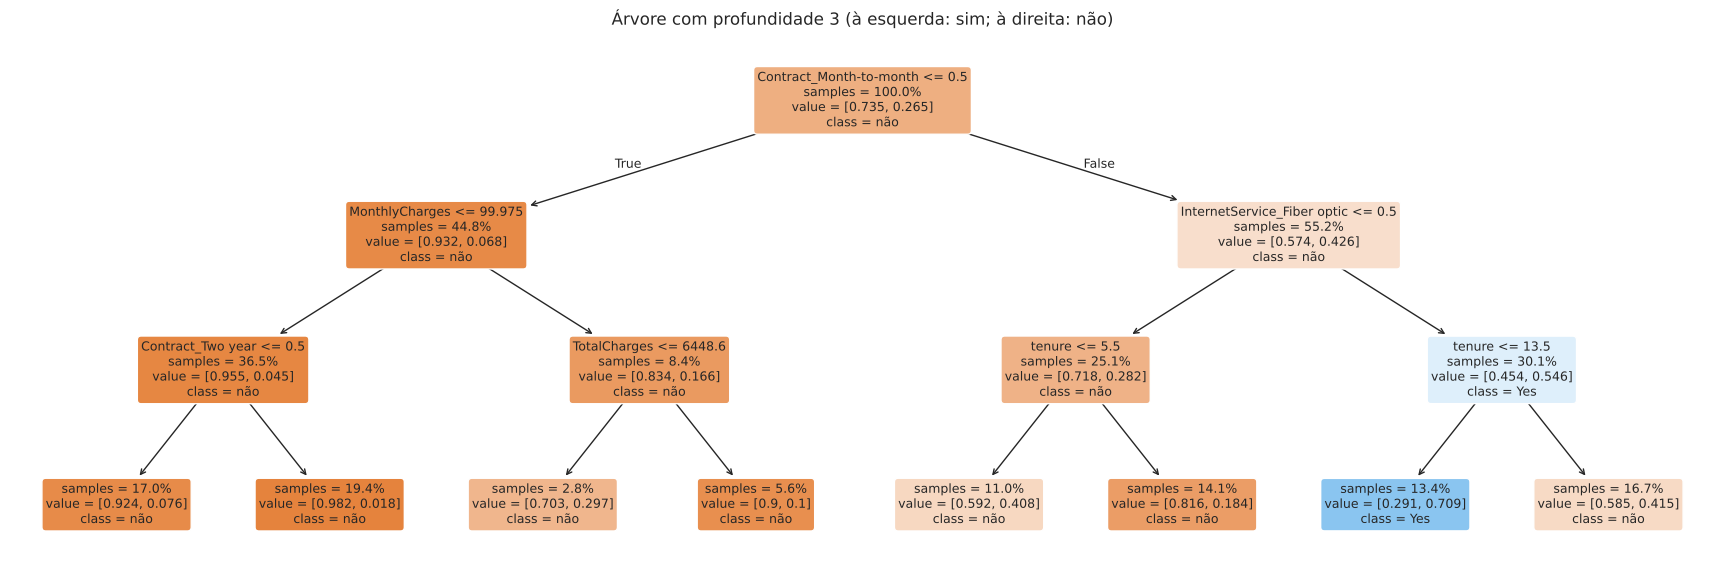

,acurácia,precisão,recall,alertas,VP,FN,custo
treino (ajuste),0.791,0.709,0.359,532,377,674,161400
validação,0.795,0.711,0.385,190,135,216,52700


In [26]:
arv3 = arvore(3).fit(X_aj, y_aj)
nomes = list(arv3.named_steps['preparo'].get_feature_names_out())
plt.figure(figsize=(22, 7))
plot_tree(arv3.named_steps['modelo'], feature_names=nomes, class_names=['não', CLASSE_POSITIVA], filled=True,
          rounded=True, proportion=True, impurity=False, fontsize=9)
plt.title('Árvore com profundidade 3 (à esquerda: sim; à direita: não)')
plt.show()
tabela({'treino (ajuste)': metricas(y_aj, arv3.predict(X_aj)), 'validação': metricas(y_val, arv3.predict(X_val))})

**Leitura.** A primeira pergunta é a mesma da regra simples: o contrato é mensal? Entre os contratos mensais, a árvore pergunta pela fibra ótica e pelo tempo de casa. A folha de maior risco (71% de cancelamento) reúne contrato mensal, fibra ótica e até 13 meses de casa. Entre os contratos longos, todas as folhas ficam abaixo de 30%. A acurácia é de 79,1% no ajuste e 79,5% na validação: não há sinal de overfitting. Com limiar 0,5, só a folha de 71% gera alertas, por isso o recall fica em 38%.

## 6.4 Complexidade: underfitting e overfitting

Árvores de profundidade 1 a 15 e sem limite, com `min_samples_leaf=1` para deixar o efeito visível. Acurácia no ajuste e na validação.

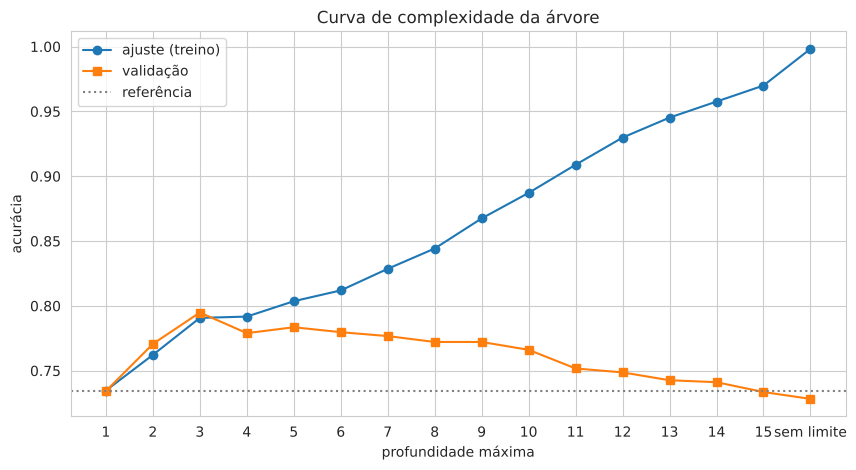

Profundidade com a melhor acurácia na validação: 3


,profundidade,folhas,acurácia ajuste,acurácia validação
0,1,2,0.735,0.734
2,3,8,0.791,0.795
9,10,322,0.887,0.766
15,sem limite,781,0.998,0.728


In [27]:
profundidades = list(range(1, 16)) + [None]
curva = []
for p in profundidades:
    m = arvore(p, min_folha=1).fit(X_aj, y_aj)
    curva.append({'profundidade': 'sem limite' if p is None else p, 'folhas': m.named_steps['modelo'].get_n_leaves(),
                  'acurácia ajuste': accuracy_score(y_aj, m.predict(X_aj)), 'acurácia validação': accuracy_score(y_val, m.predict(X_val))})
curva = pd.DataFrame(curva)
eixo = curva['profundidade'].astype(str)
plt.plot(eixo, curva['acurácia ajuste'], 'o-', label='ajuste (treino)')
plt.plot(eixo, curva['acurácia validação'], 's-', label='validação')
plt.axhline(max(y_val.mean(), 1 - y_val.mean()), color='gray', ls=':', label='referência')
plt.xlabel('profundidade máxima')
plt.ylabel('acurácia')
plt.title('Curva de complexidade da árvore')
plt.legend()
plt.show()

PROFUNDIDADE = int(curva.iloc[:-1].loc[curva.iloc[:-1]['acurácia validação'].idxmax(), 'profundidade'])
print(f'Profundidade com a melhor acurácia na validação: {PROFUNDIDADE}')
display(curva.iloc[sorted({0, 2, PROFUNDIDADE - 1, 9, len(curva) - 1})])

# Desafio 1: descomente a linha abaixo para usar, daqui em diante, uma árvore sem limite.
# PROFUNDIDADE, MIN_FOLHA = None, 1

**Leitura.** A curva repete a aula 11. Com profundidade 1, a árvore fica na referência (underfitting). A validação é máxima com profundidade 3 (79,5%) e depois cai, enquanto o ajuste sobe até 99,8% sem limite de profundidade, com 781 folhas: a árvore decora o treino (overfitting) e, na validação, fica abaixo da própria referência. A profundidade escolhida é 3.

## 6.5 Limiar de decisão pelo custo dos erros

A árvore calcula o risco de cada linha (`predict_proba`) e prevê positivo quando o risco passa do **limiar** (0,5 por padrão). Para uma linha com risco $p$, emitir o alerta custa `CUSTO_ACAO`; não emitir custa, em média, $p \times$ `CUSTO_PERDA`. Vale alertar quando $p >$ `CUSTO_ACAO / CUSTO_PERDA`: esse é o **limiar de equilíbrio**. Na prática, o limiar é escolhido pelo menor custo na validação.

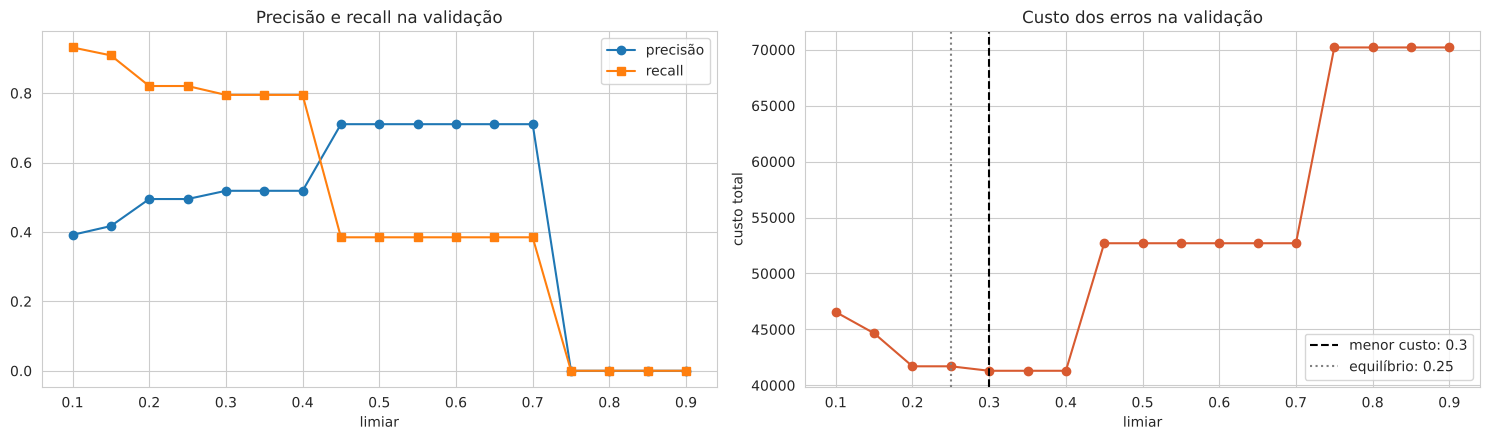

,limiar,acurácia,precisão,recall,alertas,VP,FN,custo
0,0.100,0.597,0.392,0.932,835,327,24,46550
2,0.200,0.730,0.495,0.821,582,288,63,41700
4,0.300,0.749,0.519,0.795,538,279,72,41300
6,0.400,0.749,0.519,0.795,538,279,72,41300
8,0.500,0.795,0.711,0.385,190,135,216,52700
10,0.600,0.795,0.711,0.385,190,135,216,52700
12,0.700,0.795,0.711,0.385,190,135,216,52700
14,0.800,0.734,0.000,0.000,0,0,351,70200
16,0.900,0.734,0.000,0.000,0,0,351,70200


In [28]:
modelo_val = arvore(PROFUNDIDADE).fit(X_aj, y_aj)
risco_val = modelo_val.predict_proba(X_val)[:, 1]
limiares = np.round(np.arange(0.1, 0.91, 0.05), 2)
tab_limiar = pd.DataFrame([{'limiar': t, **metricas(y_val, (risco_val >= t).astype(int))} for t in limiares])
tab_limiar = tab_limiar.astype({'alertas': int, 'VP': int, 'FN': int, 'custo': int})
LIMIAR = float(tab_limiar.loc[tab_limiar['custo'].idxmin(), 'limiar'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(tab_limiar['limiar'], tab_limiar['precisão'], 'o-', label='precisão')
axes[0].plot(tab_limiar['limiar'], tab_limiar['recall'], 's-', label='recall')
axes[0].set(xlabel='limiar', title='Precisão e recall na validação')
axes[0].legend()
axes[1].plot(tab_limiar['limiar'], tab_limiar['custo'], 'o-', color='#D85A30')
axes[1].axvline(LIMIAR, color='black', ls='--', label=f'menor custo: {LIMIAR}')
axes[1].axvline(CUSTO_ACAO / CUSTO_PERDA, color='gray', ls=':', label=f'equilíbrio: {CUSTO_ACAO / CUSTO_PERDA:.2f}')
axes[1].set(xlabel='limiar', ylabel='custo total', title='Custo dos erros na validação')
axes[1].legend()
plt.tight_layout()
plt.show()
tab_limiar.iloc[::2]

**Leitura.** Baixar o limiar aumenta o recall e reduz a precisão. Com os custos definidos (alerta de 50 USD e perda de 200 USD), o equilíbrio é 0,25, e o menor custo na validação aparece em 0,3. Como a árvore tem poucas folhas, vários limiares vizinhos dão o mesmo resultado. Com limiar 0,3, o recall vai de 39% para 80% e o custo cai de 52.700 para 41.300 USD, mesmo com quase três vezes mais alertas.

# 7. Avaliação final no teste

O modelo final é treinado com o **treino inteiro** (ajuste + validação), com a profundidade e o limiar escolhidos na seção 6, e avaliado uma única vez no teste.

,acurácia,precisão,recall,alertas,VP,FN,custo
referência,0.735,0.000,0.000,0,0,467,93400
"regra de uma pergunta, limiar 0.3",0.655,0.428,0.887,968,414,53,59000
"árvore, limiar 0,5",0.785,0.673,0.370,257,173,294,71650
"árvore, limiar 0.3",0.751,0.521,0.756,677,353,114,56650
alertar todos,0.265,0.265,1.000,1761,467,0,88050


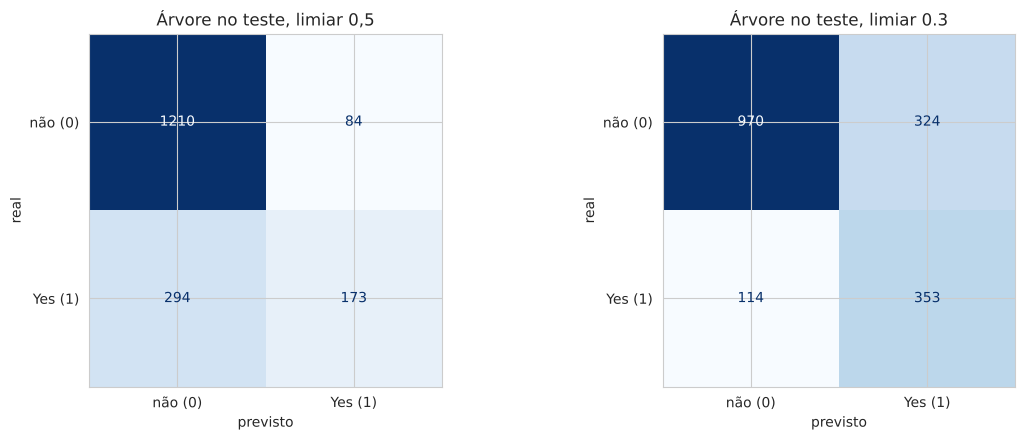

In [29]:
final = arvore(PROFUNDIDADE).fit(X_treino, y_treino)
referencia_final = Pipeline([('preparo', criar_preparo()), ('modelo', DummyClassifier(strategy='most_frequent'))]).fit(X_treino, y_treino)
regra_final = arvore(1).fit(X_treino, y_treino)
risco_teste = final.predict_proba(X_teste)[:, 1]
prev_teste = (risco_teste >= LIMIAR).astype(int)

resultado = tabela({
    'referência': metricas(y_teste, referencia_final.predict(X_teste)),
    f'regra de uma pergunta, limiar {LIMIAR}': metricas(y_teste, (regra_final.predict_proba(X_teste)[:, 1] >= LIMIAR).astype(int)),
    'árvore, limiar 0,5': metricas(y_teste, (risco_teste >= 0.5).astype(int)),
    f'árvore, limiar {LIMIAR}': metricas(y_teste, prev_teste),
    'alertar todos': metricas(y_teste, np.ones(len(y_teste), dtype=int)),
})
display(resultado)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (rot, prev) in zip(axes, [('limiar 0,5', (risco_teste >= 0.5).astype(int)), (f'limiar {LIMIAR}', prev_teste)]):
    disp = ConfusionMatrixDisplay(confusion_matrix(y_teste, prev), display_labels=['não (0)', f'{CLASSE_POSITIVA} (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set(title=f'Árvore no teste, {rot}', xlabel='previsto', ylabel='real')
plt.tight_layout()
plt.show()

    Na matriz do Scikit-learn, o real está nas linhas e o previsto nas colunas, com a classe 0 primeiro: o **VN** fica no canto superior esquerdo e o **VP** no inferior direito, ao contrário do slide da aula 11.

    **Leitura.** - Com o limiar escolhido (0,3), a árvore encontra 76% dos cancelamentos do teste (353 de 467), com precisão de 52%: de cada 2 descontos, 1 vai para quem de fato ia sair. O custo é de 56.650 USD, contra 93.400 sem fazer nada e 88.050 alertando todos.
- O limiar padrão de 0,5 tem a maior acurácia (78,5%), mas deixa passar 294 cancelamentos e custa 71.650 USD. A métrica certa depende da decisão que o modelo apoia.
- A regra de uma pergunta, com o mesmo limiar, custa 59.000 USD: a árvore economiza cerca de 2.350 USD (4%) sobre ela. A maior parte do ganho vem da pergunta sobre o contrato.
- Os resultados no teste ficam próximos dos da validação: a escolha feita sem olhar o teste se confirmou.

# 8. Análise de erros e interpretação

## 8.1 O que a árvore usa

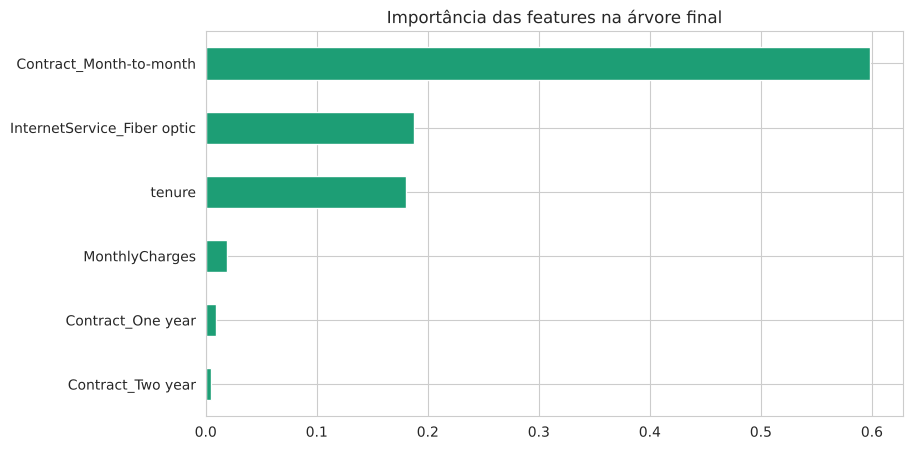

In [30]:
imp = pd.Series(final.named_steps['modelo'].feature_importances_, index=final.named_steps['preparo'].get_feature_names_out())
imp = imp[imp > 0].sort_values().tail(12)
imp.plot.barh(color='#1D9E75', figsize=(9, 5), title='Importância das features na árvore final')
plt.show()

**Leitura.** A árvore usa poucas variáveis: o contrato mensal concentra cerca de 60% da importância, seguido de fibra ótica e tempo de casa. `gender` e os serviços de streaming não aparecem. Importância descreve o que o modelo usa, não causa: o contrato mensal não faz o cliente cancelar, mas identifica quem está livre para sair a qualquer momento.

## 8.2 Onde a árvore erra

In [31]:
erros = X_teste.assign(real=y_teste.values, previsto=prev_teste, risco=risco_teste.round(2))
erros['FN (caso perdido)'] = (erros['real'] == 1) & (erros['previsto'] == 0)
erros['FP (alerta desnecessário)'] = (erros['real'] == 0) & (erros['previsto'] == 1)
for c in amplitude.index[:2]:
    display(erros.groupby(c, observed=True).agg(n=('real', 'size'), positivos=('real', 'sum'), alertas=('previsto', 'sum'),
                                               FN=('FN (caso perdido)', 'sum'), FP=('FP (alerta desnecessário)', 'sum')))
print('Exemplos de casos perdidos (FN):')
erros[erros['FN (caso perdido)']].head(5)

,n,positivos,alertas,FN,FP
Contract,,,,,
Month-to-month,968,414,677,61,324
One year,366,43,0,43,0
Two year,427,10,0,10,0


,n,positivos,alertas,FN,FP
InternetService,,,,,
DSL,605,116,85,67,36
Fiber optic,773,321,533,35,247
No,383,30,59,12,41


Exemplos de casos perdidos (FN):


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaymentMethod,MonthlyCharges,TotalCharges,n_servicos,faixa_tenure,real,previsto,risco,FN (caso perdido),FP (alerta desnecessário)
1577,Female,No,Yes,Yes,17,Yes,No,Fiber optic,No,No,...,Bank transfer (automatic),98.600,"1,704.950",4,1 a 2 anos,1,0,0.220,True,False
5871,Male,No,No,No,24,Yes,Yes,DSL,Yes,No,...,Bank transfer (automatic),55.650,"1,400.550",1,1 a 2 anos,1,0,0.200,True,False
4653,Female,No,Yes,Yes,30,No,No,DSL,No,No,...,Credit card (automatic),51.200,"1,561.500",3,2 a 4 anos,1,0,0.200,True,False
1014,Male,No,Yes,Yes,18,Yes,No,DSL,No,No,...,Electronic check,57.450,990.850,2,1 a 2 anos,1,0,0.200,True,False
3799,Female,No,No,No,31,Yes,Yes,DSL,Yes,No,...,Credit card (automatic),65.250,"1,994.300",3,2 a 4 anos,1,0,0.200,True,False


**Leitura.** - Todos os alertas vão para contratos mensais. Os 53 cancelamentos de contratos de um e dois anos nunca são encontrados (todos são FN): para a árvore, esses clientes têm risco baixo.
- Os alertas desnecessários se concentram nos clientes de fibra ótica (247 de 324).
- Os casos perdidos têm, em geral, mais tempo de casa e não usam fibra: caem em folhas de risco baixo. Para encontrá-los, seria preciso outra informação, como reclamações recentes ou queda no uso do serviço.

# 9. Conclusões

1. A auditoria encontrou problemas típicos de uma base real: número lido como texto, ausentes disfarçados resolvidos por regra de domínio, categorias redundantes e um identificador.
2. A EDA mostrou que contrato, tipo de internet, forma de pagamento e tempo de casa concentram a informação sobre o cancelamento.
3. A verificação de vazamento não encontrou features suspeitas; o exemplo fictício mostra como uma coluna posterior ao evento se denuncia.
4. A árvore de profundidade 3, escolhida na validação, generaliza: acurácias parecidas no ajuste, na validação e no teste.
5. A decisão que mais mudou o resultado foi o limiar: escolhido pelo custo dos erros, reduziu o custo no teste de 71.650 para 56.650 USD.
6. Uma única pergunta (contrato mensal) já captura a maior parte do ganho; a árvore acrescenta cerca de 4%.

**Decisão: Aplicar.** O alvo existe, as features são conhecidas antes da previsão e não há vazamento, o modelo supera a referência e a regra simples no teste, e treino, validação e teste ficam próximos.

# 10. Desafios

Os mesmos desafios aparecem no notebook de regressão. Responda em uma célula de texto no fim do notebook, com os números obtidos. Cada desafio pede uma alteração pequena: faça, rode e **volte o notebook ao original** antes do próximo.

1. **Complexidade.** Em 6.4, que acurácia de ajuste e de validação tem a árvore sem limite? Quantas folhas? Depois, descomente a última linha da célula de 6.4 (`PROFUNDIDADE, MIN_FOLHA = None, 1`) e rode tudo. Compare acurácia, recall e custo no teste com os da árvore escolhida. Explique com as palavras generalização e overfitting.
2. **Custo e limiar.** Mude `CUSTO_ACAO` para 20 e depois para 150 (seção 0) e rode tudo. O que acontece com o limiar escolhido, com o número de alertas e com o recall? Explique pelo limiar de equilíbrio.
3. **Vazamento.** Em 5.3, por que `motivo_saida` acerta quase tudo sozinha e, mesmo assim, não pode entrar no modelo? Dê um exemplo de coluna com o mesmo problema no projeto do grupo.
4. **Features.** Acrescente à lista `COLUNAS_FORA` a coluna original da feature mais importante em 8.1 (por exemplo, `Contract` para `Contract_Month-to-month`) e rode tudo. Quanto pioram o recall e o custo no teste? A árvore encontrou substitutos?
5. **Referência.** A regra de uma pergunta (6.2) já supera a referência? Quanto a árvore final acrescenta a ela no teste, em recall e em custo? Vale a complexidade a mais?

# 11. Entrega: adaptação ao projeto do grupo

## O que fazer

1. *Arquivo > Salvar uma cópia no Drive* e renomeie para `oficina_ML_grupoXX.ipynb`.
2. Envie a base do projeto (ícone de pasta, à esquerda, no Colab) e, na seção 0, aponte `ARQUIVO_LOCAL` para ela e ajuste os parâmetros.
3. Reescreva a função `limpar` (1.3) com as regras da base do projeto e a função `criar_atributos` (4.1), se houver variáveis a criar. Apague ou adapte as células que começam com o comentário *Específico da base de exemplo*.
4. Rode tudo (*Ambiente de execução > Executar tudo*) e corrija o que quebrar: em geral, nomes de colunas.
5. Reescreva **todas** as células **Leitura**, a síntese 3.8 e as conclusões 9 com o que os dados do projeto mostram. Apague o texto da base de exemplo.
6. Responda aos desafios da seção 10 em uma célula de texto ao final, com os números da base de exemplo.

Se o grupo **ainda não tem base de dados**, entregue a seção 10 respondida e, no lugar da adaptação, uma célula de texto com: a decisão que a previsão apoiaria, o alvo, as features previstas, os riscos de vazamento e o que falta para obter os dados.

## Decisão sobre o projeto

A conclusão do notebook adaptado termina com uma das três decisões da aula 11, justificada com os números do notebook:

| Decisão | Quando |
|---|---|
| **Aplicar** | alvo e features existem, sem vazamento; o modelo supera a referência no teste; treino e teste próximos |
| **Investigar** | falta confirmar o alvo, a qualidade ou a quantidade dos dados; o modelo empata com a referência |
| **Não aplicar** | a pergunta do projeto é descritiva ou diagnóstica, ou os dados não permitem uma previsão honesta |

## Entrega e avaliação

Enviar no ambiente da disciplina, até as 22h00 de 29/10, o notebook adaptado **executado** (*Arquivo > Fazer download > Baixar o .ipynb*). Um notebook por grupo.

| Critério | Pontos |
|---|---|
| Desafios da seção 10 respondidos com os números da base de exemplo | 3,0 |
| Notebook executado do início ao fim com a base do projeto (parâmetros, `limpar`, `criar_atributos`) | 2,0 |
| Leituras, síntese 3.8 e alvo e features sem vazamento, coerentes com os dados do projeto | 2,5 |
| Conclusão com decisão justificada (Aplicar, Investigar ou Não aplicar) | 2,5 |
| **Total** | **10,0** |